# Atlas-DeePC: ranks 58, 61 and 63 over 1,000 seeds

This report reads the completed 3,000-rollout experiment. It never runs simulations.
Until all results exist, the first code cell deliberately refuses to report a final success rate.

All three ranks use **λg = 0.05 and Clarabel**, the same 1,000 testing seeds **311–1310**, and 320 control steps per rollout. The copied offline data and 48-chart atlas are hash-identical to the original 100-seed Clarabel study. Chart memberships, centers, and routing graph are fixed; the bases are nested prefixes with rank-dependent coefficient bounds computed by the original rule. No data collection or chart fitting occurs during evaluation.

Success requires **both** the last-30 and last-100 windows to have mean target error below 10 mm and maximum below 20 mm. Unsolved QPs retain the original zero-action behavior and count toward the outcome. Success intervals are 95% Wilson intervals; paired outcome counts compare identical seeds. Rank selection used the earlier 100-seed study, so this report evaluates the selected ranks on a separate seed panel.

Trials run serially with one numerical thread and rank order rotated within each seed. All 320 per-step times are saved; summary timing excludes the first five steps of each rollout (315,000 timed steps per rank). QP timing includes construction and solving. Offline cache setup, per-rollout goal setup, and rollout wall time are separate. These are wall-clock measurements on a shared computer. This is a separate execution session from the earlier ranks 59/62/64 evaluation; timing differences across sessions cannot be attributed to rank alone. These same 1,000 seeds have already been evaluated at other ranks, so this extension is not an untouched validation panel.


In [1]:
RUN_EXPERIMENTS = False
from pathlib import Path
from collections import Counter
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/adjacent_rank_1000_clarabel.py").exists())
RESULT = ROOT / "experiments/routed_deepc_iid/adjacent_ranks_1000_clarabel_v1"
FIGURES = RESULT / "figures"
FIGURES.mkdir(exist_ok=True)
summary = json.loads((RESULT / "summary.json").read_text())
assert summary["complete"] and summary["rollouts"] == 3000
assert summary["ranks"] == [58, 61, 63] and summary["seeds"] == list(range(311, 1311))
sys.path.insert(0, str(RESULT / "frozen_protocol/src"))
import selected_rank_1000_experiment as experiment
assert experiment.prepare() == summary["signature"]
invariance = json.loads((RESULT / "invariance_latest.json").read_text())
assert invariance["passed"] and invariance["through_seed"] == 1310
reports = {rank: json.loads((RESULT / f"rank{rank:03d}/summary.json").read_text()) for rank in summary["ranks"]}
rows, times = {}, {}
for rank, report in reports.items():
    checked = [experiment.e.load_checkpoint(experiment.e.checkpoint_path(rank, seed), rank, seed) for seed in summary["seeds"]]
    assert checked == report["results"]
    assert report["timing"]["timed_steps"] == 315000
    rows[rank] = pd.DataFrame(checked).set_index("seed").sort_index()
    assert len(rows[rank]) == 1000 and (rows[rank]["steps"] == 320).all()
    assert int((rows[rank].success_30 & rows[rank].success_100).sum()) == report["successes"]
    times[rank] = pd.DataFrame(report["timing"]["modules"]).set_index("module")
for rank in (61, 63):
    np.testing.assert_array_equal(rows[rank].exact_target_xy.tolist(), rows[58].exact_target_xy.tolist())
previous = ROOT / "experiments/routed_deepc_iid/selected_ranks_1000_clarabel_v1"
for rank in (59, 62, 64):
    for seed in summary["seeds"]:
        with np.load(previous / f"rank{rank:03d}/seed{seed}.npz", allow_pickle=False) as trace:
            old = json.loads(trace["summary"].item())
        assert old["seed"] == seed
        np.testing.assert_array_equal(old["exact_target_xy"], rows[58].loc[seed, "exact_target_xy"])
plt.rcParams.update({"figure.dpi": 125, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
colors = ["#2563eb", "#0d9488", "#d97706"]
def save(name):
    plt.tight_layout()
    plt.savefig(FIGURES / (name + ".png"), bbox_inches="tight")
    plt.show()
print("Verified 3,000 full rollouts, targets paired with ranks 59/62/64, source/data hashes, and final offline invariance audit.")


Verified 3,000 full rollouts, targets paired with ranks 59/62/64, source/data hashes, and final offline invariance audit.


## Success and tracking error

,successes,success_rate_pct,95% interval,median_tail100_mm,p90_tail100_mm,p95_tail100_mm,p99_tail100_mm,unsolved_qps
rank,,,,,,,,
58,953,95.3,93.81–96.45%,2.084,4.519,8.488,47.427,0
61,942,94.2,92.58–95.49%,1.952,4.895,11.181,45.080,0
63,957,95.7,94.26–96.79%,1.998,4.455,8.132,47.682,0


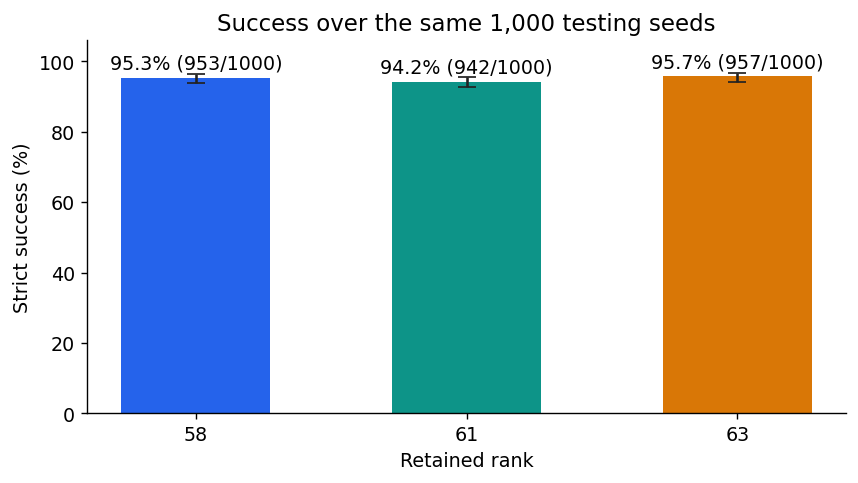

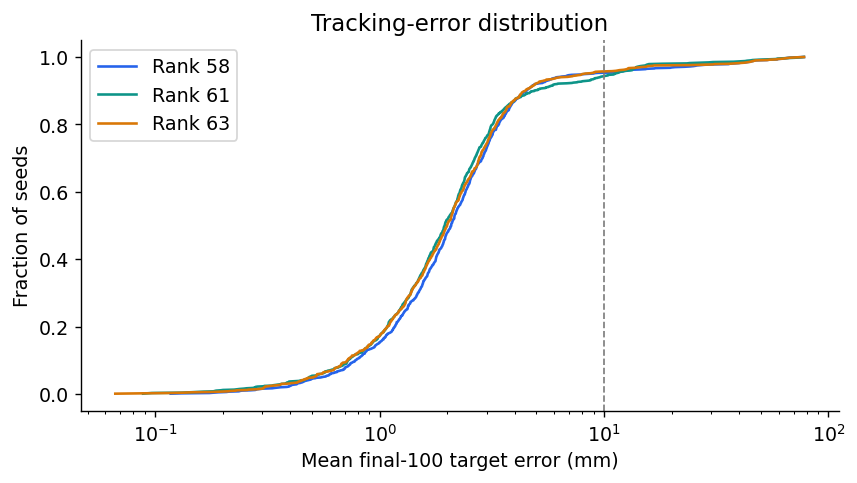

In [2]:
def wilson(k, n=1000, z=1.959963984540054):
    p = k/n
    center = (p + z*z/(2*n))/(1+z*z/n)
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/(1+z*z/n)
    return 100*np.array([center-half, center+half])
table = pd.DataFrame(summary["completed"]).set_index("rank")
table["success_rate_pct"] = table.successes/10
table["95% interval"] = ["%.2f–%.2f%%" % tuple(wilson(k)) for k in table.successes]
table["p95_tail100_mm"] = [float(np.percentile(1000*rows[r].mean_last_100,95)) for r in table.index]
table["p99_tail100_mm"] = [float(np.percentile(1000*rows[r].mean_last_100,99)) for r in table.index]
display(table[["successes", "success_rate_pct", "95% interval", "median_tail100_mm", "p90_tail100_mm", "p95_tail100_mm", "p99_tail100_mm", "unsolved_qps"]].round(3))
fig, ax = plt.subplots(figsize=(7, 4))
rates = table.success_rate_pct.to_numpy()
intervals = np.array([wilson(k) for k in table.successes])
ax.bar([str(r) for r in reports], rates, color=colors, width=.55)
ax.errorbar(range(3), rates, yerr=np.vstack([rates-intervals[:,0], intervals[:,1]-rates]), fmt="none", color="#222222", capsize=5)
for i, (rate, count) in enumerate(zip(rates, table.successes)):
    ax.text(i, min(102, intervals[i,1]+1.3), f"{rate:.1f}% ({count}/1000)", ha="center")
ax.set(xlabel="Retained rank", ylabel="Strict success (%)", ylim=(0, 106), title="Success over the same 1,000 testing seeds")
save("success")

fig, ax = plt.subplots(figsize=(7, 4))
for color, (rank, frame) in zip(colors, rows.items()):
    ax.plot(np.sort(1000*frame.mean_last_100), np.arange(1, 1001)/1000, label=f"Rank {rank}", color=color)
ax.axvline(10, color="gray", linestyle="--", linewidth=1)
ax.set(xlabel="Mean final-100 target error (mm)", ylabel="Fraction of seeds", xscale="log", title="Tracking-error distribution")
ax.legend()
save("tracking_error")


## Paired outcomes and solver statuses

In [3]:
paired = []
for a, b in ((58,61), (58,63), (61,63)):
    sa = rows[a].success_30 & rows[a].success_100
    sb = rows[b].success_30 & rows[b].success_100
    paired.append({"rank A": a, "rank B": b, "both succeed": int((sa & sb).sum()),
                   "A only": int((sa & ~sb).sum()), "B only": int((~sa & sb).sum()),
                   "both fail": int((~sa & ~sb).sum())})
display(pd.DataFrame(paired))
status_counts = {rank: dict(sum((Counter(x) for x in frame.statuses), Counter())) for rank, frame in rows.items()}
for rank, counts in status_counts.items():
    assert sum(counts.values()) == 320000
    assert counts == summary["statuses_by_rank"][str(rank)]
display(pd.DataFrame(status_counts).fillna(0).astype(int).rename_axis("Solver status"))


,rank A,rank B,both succeed,A only,B only,both fail
0,58,61,922,31,20,27
1,58,63,939,14,18,29
2,61,63,934,8,23,35


,58,61,63
Solver status,,,
optimal,320000,320000,320000


## Computation time

mean_ms  median_ms   p95_ms   p99_ms
Rank Module                                                            
58   Chart localization             0.0648     0.0599   0.0865   0.1722
     Terminal-reference selection   0.0153     0.0140   0.0190   0.0430
     Graph routing                  0.0071     0.0055   0.0083   0.0172
     Linear subspace retrieval      0.0007     0.0007   0.0010   0.0015
     QP construction and solve     34.8081    31.1788  54.2430  76.3080
     Other control-loop work        0.0335     0.0295   0.0460   0.0915
     Total online control          34.9295    31.2906  54.3974  76.5214
61   Chart localization             0.0641     0.0601   0.0861   0.1698
     Terminal-reference selection   0.0151     0.0140   0.0189   0.0425
     Graph routing                  0.0064     0.0055   0.0082   0.0170
     Linear subspace retrieval      0.0007     0.0007   0.0010   0.0015
     QP construction and solve     35.5393    31.9516  54.8316  76.6583
     Other control-loop work        0.0326     0.0295   0.0457   0.0904
     Total online control          35.6582    32.0632  54.9907  76.8777
63   Chart localization             0.0644     0.0604   0.0867   0.1717
     Terminal-reference selection   0.0155     0.0140   0.0189   0.0425
     Graph routing                  0.0066     0.0055   0.0082   0.0167
     Linear subspace retrieval      0.0007     0.0007   0.0010   0.0015
     QP construction and solve     36.5487    32.9340  56.5431  78.6689
     Other control-loop work        0.0327     0.0297   0.0463   0.0921
     Total online control          36.6685    33.0457  56.7028  78.8944

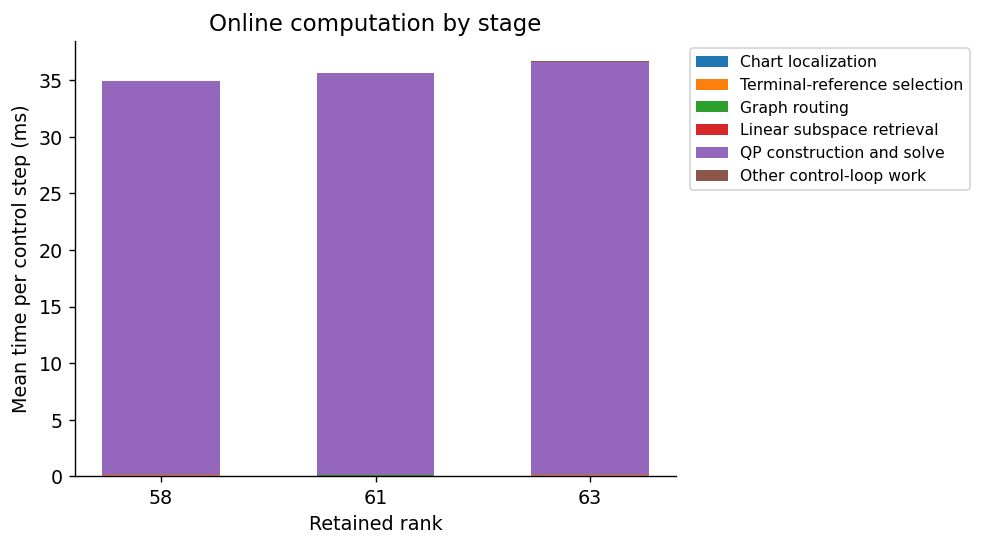

One-time goal setup per rollout (ms)


,mean,median,p95
Rank,,,
58,6.313,4.948,8.449
61,7.796,4.952,7.959
63,6.275,4.941,8.169


Offline matrix/route setup per process session (seconds)


,utc,matrix_and_route_setup_seconds_by_rank,total_load_and_setup_seconds
0,2026-09-17T14:20:59.725948+00:00,"{'58': 0.14715949981473386, '61': 0.1381528328...",0.730145
1,2026-09-17T14:21:56.627826+00:00,"{'58': 0.13562275003641844, '61': 0.1390543750...",0.495158


End-to-end rollout wall time (seconds; includes trace writing and checkpoint validation)


,count,mean,median,max
rank,,,,
58,1000,11.259,10.499,42.273
61,1000,11.496,10.704,46.378
63,1000,11.824,11.022,40.200


588828

In [4]:
timing_table = pd.concat(times, names=["Rank", "Module"])
display(timing_table[["mean_ms", "median_ms", "p95_ms", "p99_ms"]].round(4))
fig, ax = plt.subplots(figsize=(8, 4.5))
stage_names = times[58].index.drop("Total online control")
bottom = np.zeros(3)
for module in stage_names:
    values = np.array([times[r].loc[module, "mean_ms"] for r in reports])
    ax.bar([str(r) for r in reports], values, bottom=bottom, label=module, width=.55)
    bottom += values
ax.set(xlabel="Retained rank", ylabel="Mean time per control step (ms)", title="Online computation by stage")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
save("computation_time")
setup = pd.DataFrame({r: v["timing"]["one_time_goal_setup_ms"] for r, v in reports.items()}).T
setup.index.name = "Rank"
print("One-time goal setup per rollout (ms)")
display(setup.round(3))
print("Offline matrix/route setup per process session (seconds)")
display(pd.DataFrame([json.loads(p.read_text()) for p in sorted(RESULT.glob("setup_*.json"))]))
wall = [json.loads(line) for line in (RESULT / "rollout_wall_times.jsonl").read_text().splitlines()]
wall = pd.DataFrame([x for x in wall if not x["reused_checkpoint"]])
print("End-to-end rollout wall time (seconds; includes trace writing and checkpoint validation)")
display(wall.groupby("rank").seconds.agg(["count", "mean", "median", "max"]).round(3))
report = {"complete": True, "rollouts": 3000, "ranks": table.reset_index().to_dict(orient="records"), "paired_outcomes": paired,
          "statuses_by_rank": status_counts, "timing_note": summary["timing_note"],
          "timing_by_rank": {r: v["timing"] for r, v in reports.items()},
          "paired_targets_verified_against_ranks": [59, 62, 64],
          "verified_offline_invariance": True, "figures": [str(p) for p in sorted(FIGURES.glob("*.png"))]}
(RESULT / "notebook_report.json").write_text(json.dumps(report, indent=2))
